<a href="https://colab.research.google.com/github/pikey-msc/RiesgosFinancieros/blob/master/2027-1/Merton_KMV_mercado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Merton y KMV con datos de mercado
**Del precio de la acción a la distancia al default (DD), la EDF y el riesgo de una cartera.**
Versión ampliada del notebook `Merton_KMV_py.ipynb`, siguiendo el capítulo 3 de los apuntes (§2.2.5 Merton y KMV).

**Notación del curso** (distinta a la de la literatura: V, E, F):
$K_t$ = valor de los **activos**, $A_t$ = valor del **capital** (acciones), $D$ = valor nominal de la deuda, $\sigma_K$ = vol. de activos, $\sigma_A$ = vol. del capital.

| Sección | Contenido |
|---|---|
| 0 | Motor: Merton, sistema 2×2 (Newton), KMV iterativo, MLE de Duan, barrera, saltos, Vasicek |
| 1 | Merton directo: el capital es una *call*; PD, LGD endógena, spread |
| 2 | **Datos de mercado** (yfinance; si no hay red usa el *snapshot* de tu notebook) |
| 3 | Calibración $(K_0,\sigma_K)$ y sensibilidad al punto de default |
| 4 | Estimación con la serie de tiempo: KMV iterativo vs MLE vs ingenuo; DD(t) |
| 5 | Extensiones: Black–Cox (barrera), saltos de Merton, estructura temporal de PD y spread |
| 6 | Del DD a la EDF **empírica** (base de datos simulada con colas pesadas) |
| 7 | Cartera: correlaciones de activos, Gaussian copula vs Vasicek, VaR |
| 8 | Ejercicios para el alumno |
| 9 | Errores del notebook original y referencias |

> **Modo de datos.** La celda 2.1 intenta descargar con `yfinance`. Si no hay red (o falla), usa un *snapshot* con las cifras de tu notebook (WALMEX, dic-2021 / jun-2022) y una serie de precios **simulada**; el notebook lo avisa con `MODO = 'OFFLINE'`.

In [ ]:
# 0. Motor ---------------------------------------------------------------
import warnings, logging; warnings.filterwarnings('ignore'); logging.getLogger('yfinance').setLevel(logging.CRITICAL)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq, minimize
from scipy.special import gammaln
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False})
N, n_ = norm.cdf, norm.pdf
H = 1/252                                              # paso diario

def d12(K, D, r, s, T):
    d1 = (np.log(K/D) + (r + .5*s*s)*T)/(s*np.sqrt(T)); return d1, d1 - s*np.sqrt(T)

def call(K, D, r, s, T):                                # capital A = call sobre K con strike D (vectorizada)
    d1, d2 = d12(K, D, r, s, T); return K*N(d1) - D*np.exp(-r*T)*N(d2)

def merton(K0, D, r, s, T, mu=None):
    """Valuación de Merton. PD neutral = Φ(-d2); PD real usa μ; LGD endógena = 1 - E*[K_T|default]/D."""
    d1, d2 = d12(K0, D, r, s, T); A = call(K0, D, r, s, T); Dm = K0 - A; mu = r if mu is None else mu
    pdq = N(-d2); pdp = N(-(np.log(K0/D) + (mu - .5*s*s)*T)/(s*np.sqrt(T)))
    rec = K0*np.exp(r*T)*N(-d1)/(D*pdq) if pdq > 1e-300 else np.nan
    return dict(d1=d1, d2=d2, A=A, Dm=Dm, pdq=pdq, pdp=pdp, lgd=1 - rec, spread=-np.log(Dm/D)/T - r,
                delta=N(d1), eta=K0*N(d1)/A)

def solve_kmv(A0, sA, D, r, T, tol=1e-12):
    """(K0, σK) tales que  A0 = K·Φ(d1) - D e^{-rT} Φ(d2)  y  σA·A0 = σK·K·Φ(d1).
    Newton 2x2 con jacobiano analítico; respaldo anidado (brentq) si no converge. Devuelve K0, σK, trayectoria, método."""
    B = D*np.exp(-r*T); sq = np.sqrt(T); x = np.array([A0 + B, sA*A0/(A0 + B)]); tr = [x.copy()]
    for _ in range(100):
        K, s = x
        if K <= 0 or s <= 0: break
        d1, d2 = d12(K, D, r, s, T)
        F = np.array([K*N(d1) - B*N(d2) - A0, s*K*N(d1) - sA*A0])
        J = np.array([[N(d1), K*n_(d1)*sq], [s*N(d1) + n_(d1)/sq, K*N(d1) - K*n_(d1)*d2]])
        if np.abs(F).max() < tol*max(A0, 1): return x[0], x[1], tr, 'newton'
        try: dx = np.linalg.solve(J, -F)
        except np.linalg.LinAlgError: break
        t = 1.
        while t > 1e-6 and (x + t*dx).min() <= 0: t /= 2
        x = x + t*dx; tr.append(x.copy())
    Kof = lambda s: brentq(lambda K: call(K, D, r, s, T) - A0, A0*(1 - 1e-12), A0 + B, xtol=1e-14*A0)
    s = brentq(lambda s: s*Kof(s)*N(d12(Kof(s), D, r, s, T)[0]) - sA*A0, 1e-6, sA*1.0000001)
    return Kof(s), s, tr, 'brentq'

dd_kmv = lambda K, D, s: (K - D)/(s*K)                  # DD lineal de KMV
dd_mer = lambda K, D, s, T, mu: (np.log(K/D) + (mu - .5*s*s)*T)/(s*np.sqrt(T))   # DD de Merton (= d2 con μ)

def naive_bs(E, D, sE, r_past, T=1.):
    """Ingenuo de Bharath-Shumway (2008): sin resolver el sistema."""
    sV = E/(E + D)*sE + D/(E + D)*(.05 + .25*sE)
    dd = (np.log((E + D)/D) + (r_past - .5*sV*sV)*T)/(sV*np.sqrt(T)); return dd, N(-dd), sV

def invert(A, D, r, s, T):
    """K_t con call(K_t; σ) = A_t, vectorizado por bisección (A es un arreglo)."""
    lo = np.asarray(A, float).copy(); hi = lo + D*np.exp(-r*T)
    for _ in range(70):
        mid = .5*(lo + hi); f = call(mid, D, r, s, T) - A; hi = np.where(f > 0, mid, hi); lo = np.where(f > 0, lo, mid)
    return .5*(lo + hi)

def kmv_iter(A, D, r, T, h=H, it=200, tol=1e-10):
    """Algoritmo iterativo de KMV (Crosbie): invierte BS día a día, σK = desv. est. de log-rend. de K̂_t, hasta el punto fijo."""
    lr = np.diff(np.log(A)); sE = lr.std(ddof=1)/np.sqrt(h); s = sE*A[-1]/(A[-1] + D); tr = [s]
    for _ in range(it):
        sn = np.diff(np.log(invert(A, D, r, s, T))).std(ddof=1)/np.sqrt(h); tr.append(sn)
        if abs(sn - s) < tol: s = sn; break
        s = sn
    K = invert(A, D, r, s, T); mu = np.diff(np.log(K)).mean()/h + .5*s*s
    return dict(sK=s, mu=mu, K=K, trace=np.array(tr), sE=sE)

def mle_duan(A, D, r, T, h=H, x0=(.05, np.log(.2))):
    """MLE de datos transformados (Duan 1994): log-verosimilitud de K_t (lognormal) menos log Φ(d1) (jacobiano)."""
    def nll(p):
        mu, s = p[0], np.exp(p[1]); K = invert(A, D, r, s, T); z = (np.diff(np.log(K)) - (mu - .5*s*s)*h)/(s*np.sqrt(h))
        return -np.sum(-np.log(s*np.sqrt(h)) - np.log(K[1:]) - .5*np.log(2*np.pi) - .5*z*z - np.log(N(d12(K[1:], D, r, s, T)[0])))
    o = minimize(nll, x0, method='Nelder-Mead', options=dict(xatol=1e-9, fatol=1e-10, maxiter=4000)); return o.x[0], np.exp(o.x[1])

def black_cox_pd(K0, B, mu, s, T):
    """P(min_{t<=T} K_t <= B) con barrera plana B<K0 (Black-Cox 1976)."""
    b = np.log(B/K0); m = mu - .5*s*s; st = s*np.sqrt(T)
    return N((b - m*T)/st) + np.exp(2*m*b/s**2)*N((b + m*T)/st)

def jump_pd(K0, D, mu, s, T, lam, mj, dj, nmax=60):
    """P(K_T <= D) con saltos lognormales (Merton 1976), deriva compensada. ln(1+k)=mj+dj²/2."""
    k = np.exp(mj + .5*dj*dj) - 1; n = np.arange(nmax); T = np.atleast_1d(T)[:, None]
    w = np.exp(-lam*T + n*np.log(np.maximum(lam*T, 1e-300)) - gammaln(n + 1))
    m = (mu - .5*s*s - lam*k)*T + n*mj; v = s*s*T + n*dj*dj
    return (w*N((np.log(D/K0) - m)/np.sqrt(v))).sum(1)

def simulate(K0, D, r, mu, sK, T, n, noise=0., seed=1):
    """Activos GBM diarios; capital = call con vencimiento rodante T (convención KMV); ruido multiplicativo opcional."""
    rng = np.random.default_rng(seed)
    K = K0*np.exp(np.concatenate([[0], np.cumsum((mu - .5*sK**2)*H + sK*np.sqrt(H)*rng.standard_normal(n))]))
    return K, call(K, D, r, sK, T)*np.exp(noise*rng.standard_normal(n + 1))

vasicek_var = lambda pd_, rho, lgd, al: lgd*N((norm.ppf(pd_) + np.sqrt(rho)*norm.ppf(al))/np.sqrt(1 - rho))
def bvn_cdf(h_, k_, rho, m=2000):
    x = np.linspace(-9, h_, m); return np.trapezoid(n_(x)*N((k_ - rho*x)/np.sqrt(1 - rho*rho)), x)
def rho_edf(p1, p2, ra):
    j = bvn_cdf(norm.ppf(p1), norm.ppf(p2), ra); return (j - p1*p2)/np.sqrt(p1*(1 - p1)*p2*(1 - p2)), j

# --- verificación con el ejemplo del PDF (Crosbie): A0=3, D=10, σA=40%, r=5%, T=1 ---
K0, sK, _, met = solve_kmv(3, .4, 10, .05, 1)
assert abs(K0 - 12.51) < .01 and abs(sK - .0961) < 1e-4
print(f'Crosbie: K0 = {K0:.4f}, σK = {sK:.4%}  ({met})  | DD KMV = {dd_kmv(K0, 10, sK):.3f}  (el PDF dice 2.82: ver sección 9)')

Crosbie: K0 = 12.5116, σK = 9.6090%  (newton)  | DD KMV = 2.089  (el PDF dice 2.82: ver sección 9)


## 1. Merton directo: el capital es una opción
Con $K_0$, $\sigma_K$, $D$, $r$, $T$ conocidos: $A_T=(K_T-D)^+$ (call) y $D_T=\min(K_T,D)=D-(D-K_T)^+$.
Bajo $\mathbb{Q}$: $\;\mathrm{PD}=\Phi(-d_2)$; bajo $\mathbb{P}$ se reemplaza $r$ por $\mu$. La **LGD sale del modelo**: $\;1-\dfrac{K_0e^{rT}\Phi(-d_1)}{D\,\Phi(-d_2)}$.

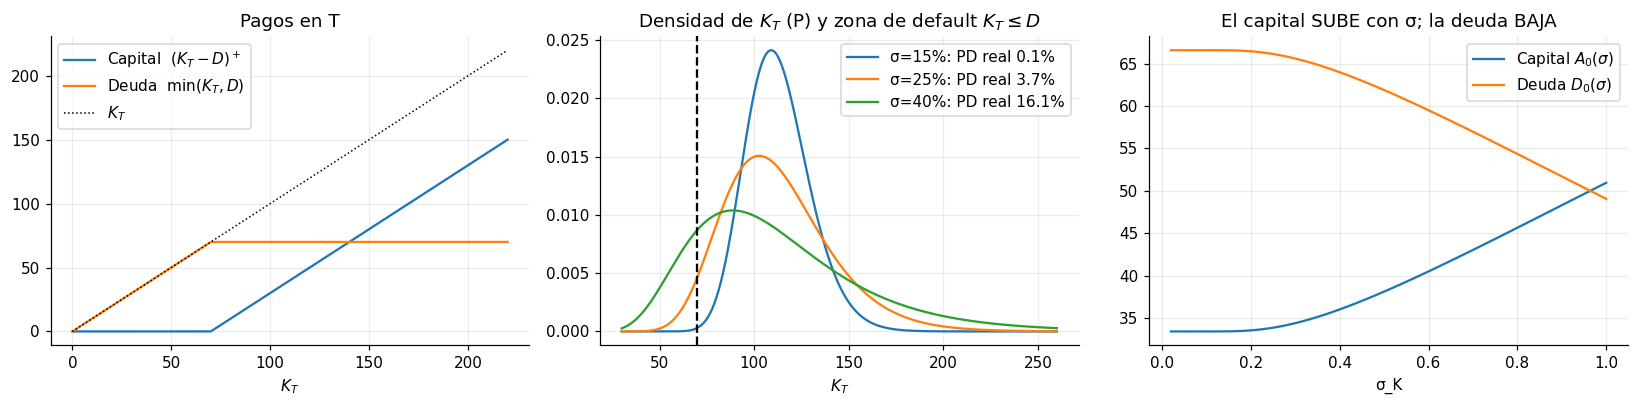

d1         1.75170
d2         1.50170
A         33.85646
Dm        66.14354
pdq        0.06659
pdp        0.03740
lgd        0.09981
spread     0.00667
delta      0.96009
eta        2.83576
Paridad  A0 + D0 − K0 = 0.0


In [ ]:
# 1. Merton directo -------------------------------------------------------
K0, D, r, T, mu = 100., 70., .05, 1., .12
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
kt = np.linspace(0, 220, 400)
ax[0].plot(kt, np.maximum(kt - D, 0), label='Capital  $(K_T-D)^+$'); ax[0].plot(kt, np.minimum(kt, D), label='Deuda  $\\min(K_T,D)$'); ax[0].plot(kt, kt, 'k:', lw=1, label='$K_T$')
ax[0].set(title='Pagos en T', xlabel='$K_T$'); ax[0].legend()
for s in (.15, .25, .40):
    m_ = merton(K0, D, r, s, T, mu); x = np.linspace(30, 260, 400); sq = s*np.sqrt(T); mp = np.log(K0) + (mu - .5*s*s)*T
    ax[1].plot(x, n_((np.log(x) - mp)/sq)/(x*sq), label=f'σ={s:.0%}: PD real {m_["pdp"]:.1%}')
ax[1].axvline(D, color='k', ls='--'); ax[1].set(title='Densidad de $K_T$ (P) y zona de default $K_T\\leq D$', xlabel='$K_T$'); ax[1].legend()
ss = np.linspace(.02, 1, 80); ax[2].plot(ss, call(K0, D, r, ss, T), label='Capital $A_0(\\sigma)$'); ax[2].plot(ss, K0 - call(K0, D, r, ss, T), label='Deuda $D_0(\\sigma)$')
ax[2].set(title='El capital SUBE con σ; la deuda BAJA', xlabel='σ_K'); ax[2].legend(); plt.tight_layout(); plt.show()
m_ = merton(K0, D, r, .25, T, mu)
print(pd.Series({k: m_[k] for k in ['d1', 'd2', 'A', 'Dm', 'pdq', 'pdp', 'lgd', 'spread', 'delta', 'eta']}).round(5).to_string())
print('Paridad  A0 + D0 − K0 =', m_['A'] + m_['Dm'] - K0)

## 2. Datos de mercado
`load_firm` obtiene precio, acciones, capital de mercado y pasivos (corto/largo plazo) de Yahoo Finance.
**Punto de default** (KMV): pasivo de corto plazo + ½ pasivo de largo plazo. Con `OFFLINE` se usa el *snapshot* de tu notebook.

MODO = LIVE | WALMEX.MX | último cierre 54.66 | acciones 17.220 mm | A0 (capital de mercado) = 941.3 mm
       monto (mm)              comentario
CP         169.72      pasivo corto plazo
LP          89.98      pasivo largo plazo
Total      259.69            pasivo total
D          214.70     D = CP + ½ LP (KMV)
A0         941.26  A0 = precio × acciones
σ_A diaria anualizada (toda la muestra) = 25.76%   (2234 rendimientos)


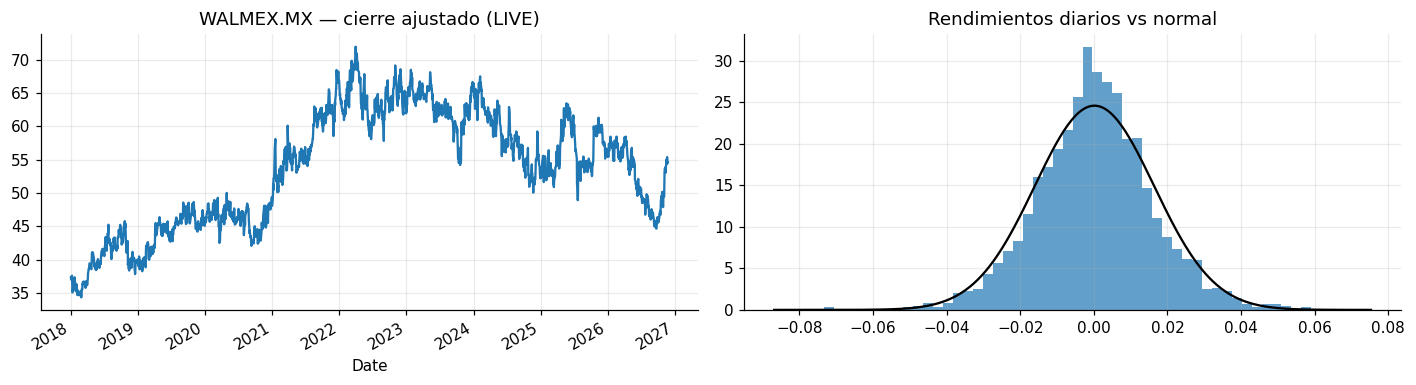

In [ ]:
# 2.1 Carga de datos (yfinance) o snapshot offline ---------------------------
TICKER, INICIO, USE_YF = 'WALMEX.MX', '2018-01-01', True
SNAP = dict(ticker='WALMEX.MX', shares=17461399552., mcap=1180739829760., std=132.7085e9, tl=208.5075e9, debt=65.2797e9, last=67.62, vol=.2643, ap=96.63788e9)

def _pick(bs, *names):
    for n in names:
        if n in bs.index:
            v = bs.loc[n].dropna()
            if len(v): return float(v.iloc[0])
    return np.nan

def load_firm(tic, start=INICIO, use_yf=USE_YF, seed=7):
    """→ dict(ticker, modo, px (Serie de cierres), shares, mcap, std, ltd, D_kmv, ...). Montos en unidades monetarias."""
    if use_yf:
        try:
            import yfinance as yf
            t = yf.Ticker(tic); px = t.history(start=start, auto_adjust=True)['Close'].dropna(); px.index = pd.DatetimeIndex(px.index).tz_localize(None)
            info = t.info; sh = info.get('sharesOutstanding') or getattr(t.fast_info, 'shares', None); bs = t.balance_sheet
            cl = _pick(bs, 'Current Liabilities', 'Total Current Liabilities'); tl = _pick(bs, 'Total Liabilities Net Minority Interest', 'Total Liab', 'Total Liabilities')
            if len(px) > 300 and sh and np.isfinite(cl) and np.isfinite(tl):
                return dict(ticker=tic, modo='LIVE', px=px, shares=float(sh), mcap=float(px.iloc[-1]*sh), std=cl, ltd=tl - cl, tl=tl)
            raise ValueError('datos incompletos en Yahoo')
        except Exception as e: print(f'[{tic}] yfinance falló ({type(e).__name__}: {str(e)[:70]}) → snapshot OFFLINE')
    rng = np.random.default_rng(seed); n = 1300; z = rng.standard_normal(n)
    lp = np.concatenate([[0], np.cumsum((.08 - .5*SNAP['vol']**2)*H + SNAP['vol']*np.sqrt(H)*z)]); px = SNAP['last']*np.exp(lp - lp[-1])
    return dict(ticker=SNAP['ticker'], modo='OFFLINE', px=pd.Series(px, index=pd.bdate_range(end='2022-06-13', periods=n + 1)), shares=SNAP['shares'],
                mcap=SNAP['mcap'], std=SNAP['std'], ltd=SNAP['tl'] - SNAP['std'], tl=SNAP['tl'])

F = load_firm(TICKER); MODO = F['modo']
F['D'] = F['std'] + .5*F['ltd']                          # punto de default KMV
ret = np.log(F['px']).diff().dropna(); F['sE'] = ret.std()*np.sqrt(252)
print(f"MODO = {MODO} | {F['ticker']} | último cierre {F['px'].iloc[-1]:.2f} | acciones {F['shares']/1e9:.3f} mm | A0 (capital de mercado) = {F['mcap']/1e9:,.1f} mm")
print(pd.DataFrame({'monto (mm)': [F['std']/1e9, F['ltd']/1e9, F['tl']/1e9, F['D']/1e9, F['mcap']/1e9], 'comentario': ['pasivo corto plazo', 'pasivo largo plazo', 'pasivo total', 'D = CP + ½ LP (KMV)', 'A0 = precio × acciones']},
                   index=['CP', 'LP', 'Total', 'D', 'A0']).round(2).to_string())
print(f"σ_A diaria anualizada (toda la muestra) = {F['sE']:.2%}   ({len(ret)} rendimientos)")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6)); F['px'].plot(ax=ax[0], title=f"{F['ticker']} — cierre ajustado ({MODO})"); ax[1].hist(ret, 60, density=True, alpha=.7)
x = np.linspace(ret.min(), ret.max(), 300); ax[1].plot(x, norm.pdf(x, ret.mean(), ret.std()), 'k'); ax[1].set(title='Rendimientos diarios vs normal'); plt.tight_layout(); plt.show()

In [10]:
# ⚠ K0 NO se toma de Yahoo: compara el K0 calibrado con los "atajos" que la gente usa
ev = np.nan
if MODO == 'LIVE':
    try: import yfinance as yf; ev = float(yf.Ticker(F['ticker']).info.get('enterpriseValue') or np.nan)
    except Exception as e_: print('EV de Yahoo no disponible:', type(e_).__name__)
prox = {'K0 calibrado (KMV)': K0c, 'EV Yahoo (enterpriseValue)': ev, 'A0 + D  (ingenuo B–S)': A0 + F['D'], 'A0 + pasivo total': A0 + F['std'] + F['ltd']}
cmp_ = pd.DataFrame({'K0 (mm)': {k: v/1e9 for k, v in prox.items()}}); cmp_['vs KMV'] = cmp_['K0 (mm)']/(K0c/1e9) - 1
cmp_['DD si K0=este y σK=σA·A0/K0'] = [dd_kmv(v, F['D'], sA*A0/v) if np.isfinite(v) else np.nan for v in prox.values()]; cmp_.loc['K0 calibrado (KMV)', 'DD si K0=este y σK=σA·A0/K0'] = dd_kmv(K0c, F['D'], sKc)
print('\n' + cmp_.to_string(float_format='{:,.4f}'.format, na_rep='n/d'))
print('⚠️  ADVERTENCIA: K0 (valor de mercado de los ACTIVOS) no cotiza en ningún lado. Yahoo da capital de mercado (A0) y enterprise value = capitalización + deuda financiera − caja:')
print('    el EV omite pasivos operativos (p. ej. cuentas por pagar), resta caja (que es activo) y no incluye la opcionalidad de la deuda. Sirve como chequeo de cordura, NO como K0.')
print('    Tomar K0 = EV obliga además a inventar σK; eso es lo que hacía el notebook original (K0=EV, A0/2, resolver por D) y por eso fsolve no convergía.')
if MODO != 'LIVE': print('    (modo OFFLINE: el EV de Yahoo no está disponible; se muestran sólo los atajos A0+D y A0+pasivo total.)')


                              K0 (mm)  vs KMV  DD si K0=este y σK=σA·A0/K0
K0 calibrado (KMV)         1,145.4915  0.0000                       3.8395
EV Yahoo (enterpriseValue)   993.6866 -0.1325                       3.2133
A0 + D  (ingenuo B–S)      1,155.9628  0.0091                       3.8827
A0 + pasivo total          1,200.9511  0.0484                       4.0683
⚠️  ADVERTENCIA: K0 (valor de mercado de los ACTIVOS) no cotiza en ningún lado. Yahoo da capital de mercado (A0) y enterprise value = capitalización + deuda financiera − caja:
    el EV omite pasivos operativos (p. ej. cuentas por pagar), resta caja (que es activo) y no incluye la opcionalidad de la deuda. Sirve como chequeo de cordura, NO como K0.
    Tomar K0 = EV obliga además a inventar σK; eso es lo que hacía el notebook original (K0=EV, A0/2, resolver por D) y por eso fsolve no convergía.


## 3. Calibración KMV: de $(A_0,\sigma_A,D)$ a $(K_0,\sigma_K)$
Se resuelve $\;G_1=K\Phi(d_1)-De^{-rT}\Phi(d_2)-A_0=0,\quad G_2=\sigma K\Phi(d_1)-\sigma_AA_0=0$.
**En KMV $D$ es un dato** (el punto de default) y las incógnitas son $K_0,\sigma_K$ (tu notebook original resolvía por $D$: ver §9).

D_como       sólo CP CP + ½ LP (KMV) CP + LP (total)
D              169.7           214.7           259.7
K0              1103            1145            1188
sK            0.2198          0.2116           0.204
eta            1.172           1.217           1.262
DD_KMV         3.849            3.84            3.83
d2              8.63           8.042           7.597
PD_Q       3.073e-18       4.422e-16        1.51e-14
PD_P       4.101e-19       6.253e-17       2.208e-15
EDF_normal  5.94e-05       6.164e-05       6.395e-05
LGD_end      0.02424         0.02493         0.02534
iters              0               0               0
metodo        newton          newton          newton

→ El punto de partida YA es la solución: con Φ(d1)≈Φ(d2)≈1 (deuda casi libre de riesgo) A0 = K0 − D e^{-rT} y σK = σA·A0/K0.


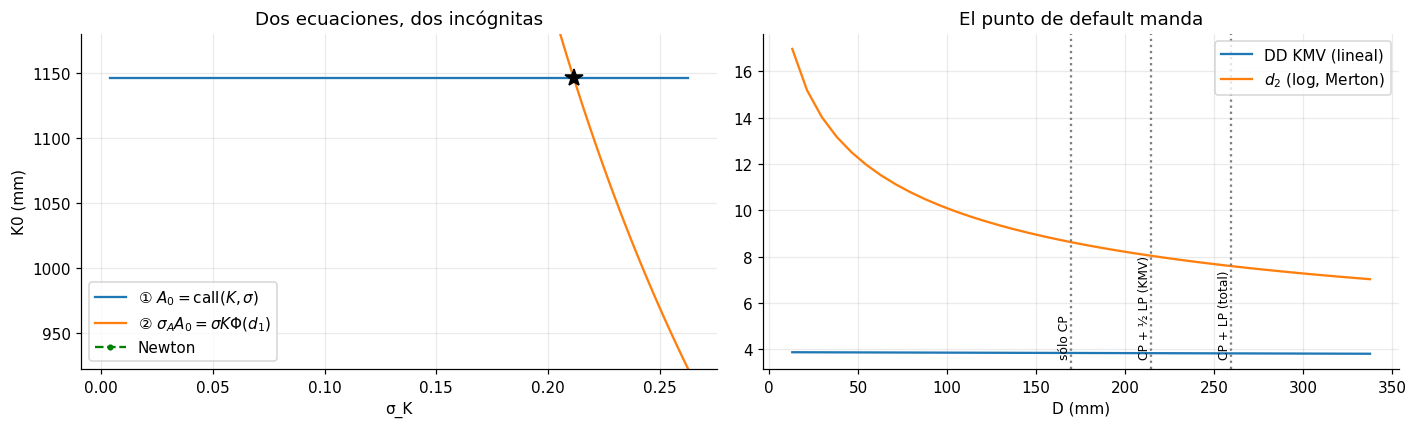

In [8]:
# 3. Calibración y sensibilidad al punto de default ---------------------------
def bis(f, lo, hi, n=200, log=False):
    """Bisección vectorizada, f creciente con f(lo)<=0<=f(hi). No lanza error de bracket."""
    lo, hi = np.asarray(lo, float).copy(), np.asarray(hi, float).copy()
    for _ in range(n):
        mid = np.sqrt(lo*hi) if log else .5*(lo + hi); up = f(mid) > 0; hi = np.where(up, mid, hi); lo = np.where(up, lo, mid)
    return .5*(lo + hi)

r, T, mu, lgd = .05, 1., .10, .45
A0, sA = F['mcap'], F['sE']
defs = {'sólo CP': F['std'], 'CP + ½ LP (KMV)': F['D'], 'CP + LP (total)': F['std'] + F['ltd']}
rows = []
for nom, D_ in defs.items():
    K_, s_, tr, met = solve_kmv(A0, sA, D_, r, T); m_ = merton(K_, D_, r, s_, T, mu)
    rows.append(dict(D_como=nom, D=D_/1e9, K0=K_/1e9, sK=s_, eta=sA/s_, DD_KMV=dd_kmv(K_, D_, s_), d2=m_['d2'], PD_Q=m_['pdq'], PD_P=m_['pdp'], EDF_normal=N(-dd_kmv(K_, D_, s_)), LGD_end=m_['lgd'], iters=len(tr) - 1, metodo=met))
tab = pd.DataFrame(rows).set_index('D_como'); pd.options.display.float_format = '{:.4g}'.format; print(tab.T.to_string())
K0c, sKc, tr, _ = solve_kmv(A0, sA, F['D'], r, T)
if len(tr) == 1: print('\n→ El punto de partida YA es la solución: con Φ(d1)≈Φ(d2)≈1 (deuda casi libre de riesgo) A0 = K0 − D e^{-rT} y σK = σA·A0/K0.')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sx = np.linspace(.004, sA*1.02, 120); B_ = F['D']*np.exp(-r*T)
K1 = invert(np.full(len(sx), A0), F['D'], r, sx, T)                  # ① K(σ): bisección vectorizada
K2 = bis(lambda k: sx*k*N(d12(k, F['D'], r, sx, T)[0]) - sA*A0, sA*A0/sx, sA*A0/sx*1e6, log=True)   # ② K(σ)
ax[0].plot(sx, K1/1e9, label='① $A_0=\\mathrm{call}(K,\\sigma)$'); ax[0].plot(sx, K2/1e9, label='② $\\sigma_AA_0=\\sigma K\\Phi(d_1)$'); ax[0].plot(*zip(*[(s, k/1e9) for k, s in tr]), 'o--', ms=3, color='g', label='Newton')
ax[0].plot(sKc, K0c/1e9, 'k*', ms=12); ax[0].set(ylim=(A0/1e9*.98, (A0 + B_)/1e9*1.03), xlabel='σ_K', ylabel='K0 (mm)', title='Dos ecuaciones, dos incógnitas'); ax[0].legend()
Dg = np.linspace(.05, 1.3, 40)*(F['std'] + F['ltd']); res = [(lambda s: (dd_kmv(s[0], d, s[1]), d12(s[0], d, r, s[1], T)[1]))(solve_kmv(A0, sA, d, r, T)[:2]) for d in Dg]
ax[1].plot(Dg/1e9, [x[0] for x in res], label='DD KMV (lineal)'); ax[1].plot(Dg/1e9, [x[1] for x in res], label='$d_2$ (log, Merton)')
for nom, d_ in defs.items(): ax[1].axvline(d_/1e9, color='gray', ls=':'); ax[1].text(d_/1e9, .03, nom, rotation=90, fontsize=8, transform=ax[1].get_xaxis_transform(), va='bottom', ha='right')
ax[1].set(xlabel='D (mm)', title='El punto de default manda'); ax[1].legend(); plt.tight_layout(); plt.show()

K0 (activos)                            1145.49
σK                                     0.211632
D (punto de default)                    214.705
D/K0                                   0.187435
A0 modelo (call)                        941.258
A0 mercado                              941.258
D0 modelo                               204.234
D e^(-rT) (libre de riesgo)             204.234
d2                                      8.04193
PD neutral Φ(−d2)                   4.42158e-16
PD real (μ)                         6.25292e-17
LGD endógena                          0.0249302
spread (pb; ≈0 = ruido numérico)   -7.07767e-12
Δ=Φ(d1)                                       1
η=K0Φ(d1)/A0                            1.21698

Para PD neutral = 1%:  σK* = 65.0% (3.1× la actual)  |  caída de activos h* = 70.2%  |  D* = 720 mm (3.4× la deuda actual, D/K0 = 62.8%)
              fórmula  Monte Carlo
PD neutral       0.01      0.00998
A0 (call)       941.6        942.3
LGD endógena   0.1828       0.1835


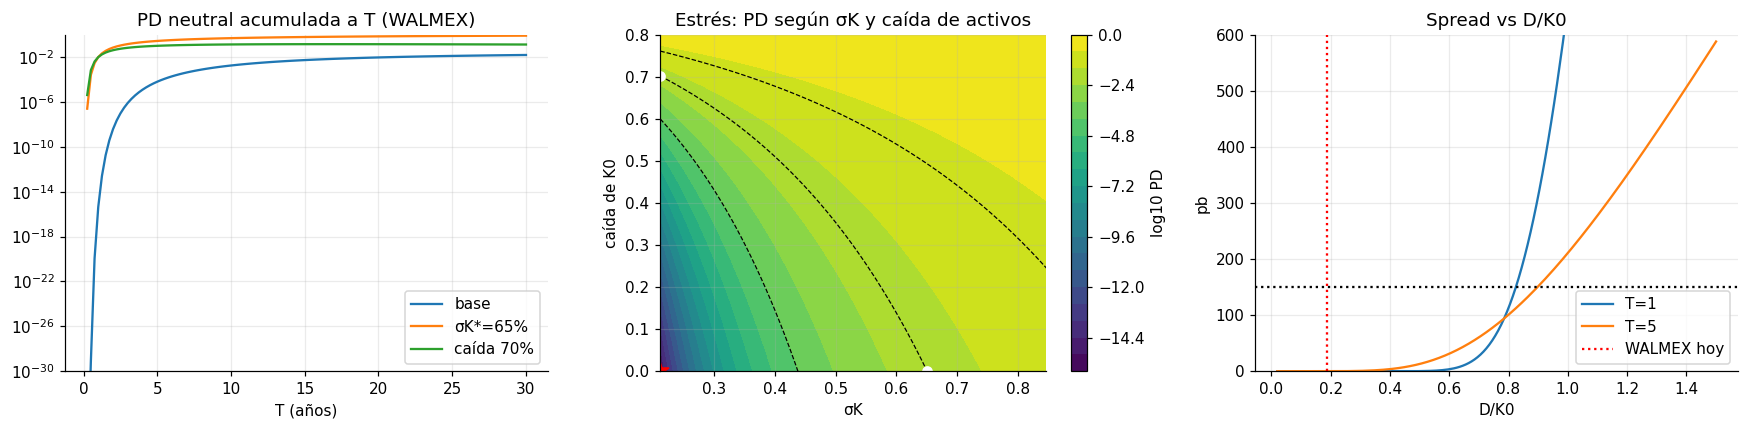

Capacidad de deuda (spread ≤ 150 pb): {'T=1': 'D/K0 = 82.5%  →  D = 945 mm  (4.4× la actual)', 'T=5': 'D/K0 = 89.8%  →  D = 1,028 mm  (4.8× la actual)'}


In [9]:
# EJERCICIO A · MERTON (dirección directa) con WALMEX. Datos del modelo: K0c, sKc (celda 3), D = CP + ½LP, r, T, μ. Cifras en mm de pesos.
Kb, sK_, Db, A_mkt = K0c/1e9, sKc, F['D']/1e9, F['mcap']/1e9
m = merton(Kb, Db, r, sK_, T, mu)
print(pd.Series({'K0 (activos)': Kb, 'σK': sK_, 'D (punto de default)': Db, 'D/K0': Db/Kb, 'A0 modelo (call)': m['A'], 'A0 mercado': A_mkt, 'D0 modelo': m['Dm'], 'D e^(-rT) (libre de riesgo)': Db*np.exp(-r*T),
                 'd2': m['d2'], 'PD neutral Φ(−d2)': m['pdq'], 'PD real (μ)': m['pdp'], 'LGD endógena': m['lgd'], 'spread (pb; ≈0 = ruido numérico)': m['spread']*1e4, 'Δ=Φ(d1)': m['delta'], 'η=K0Φ(d1)/A0': m['eta']}).to_string(float_format='{:.6g}'.format))

# (i) Prueba inversa: ¿cuánto hay que empujar el modelo para que WALMEX tenga 1% de PD neutral a T? (cada una sola, ceteris paribus)
pdq = lambda K, D_, s_, t=T: N(-d12(K, D_, r, s_, t)[1]); obj = .01                      # PD creciente en σ, haircut y D ⇒ bis válida
s_st = float(bis(lambda s_: pdq(Kb, Db, s_) - obj, sK_, 8.));  h_st = float(bis(lambda h: pdq(Kb*(1 - h), Db, sK_) - obj, 0., .999));  D_st = float(bis(lambda D_: pdq(Kb, D_, sK_) - obj, Db, 50*Kb))
print(f'\nPara PD neutral = 1%:  σK* = {s_st:.1%} ({s_st/sK_:.1f}× la actual)  |  caída de activos h* = {h_st:.1%}  |  D* = {D_st:,.0f} mm ({D_st/Db:.1f}× la deuda actual, D/K0 = {D_st/Kb:.1%})')

# (ii) Validación Monte Carlo en el punto de estrés σK* (ahí la PD ya es medible; con la PD base de ~1e-20 el MC no ve nada)
rng = np.random.default_rng(0); M = 2_000_000; KQ = Kb*np.exp((r - .5*s_st**2)*T + s_st*np.sqrt(T)*rng.standard_normal(M)); dq = KQ <= Db; ms = merton(Kb, Db, r, s_st, T, mu)
print(pd.DataFrame({'fórmula': [ms['pdq'], ms['A'], ms['lgd']], 'Monte Carlo': [dq.mean(), np.exp(-r*T)*np.maximum(KQ - Db, 0).mean(), 1 - KQ[dq].mean()/Db]}, index=['PD neutral', 'A0 (call)', 'LGD endógena']).round(5).to_string())

# (iii) Gráficas: PD(T) y spread(T) · mapa de estrés (σ × caída de activos) · capacidad de deuda
spr = lambda K, D_, s_, t: -np.log((K - call(K, D_, r, s_, t))/D_)/t - r
fig, ax = plt.subplots(1, 3, figsize=(16, 4)); Ts = np.linspace(.25, 30, 120)
for s_, h, lb in ((sK_, 0, 'base'), (s_st, 0, f'σK*={s_st:.0%}'), (sK_, h_st, f'caída {h_st:.0%}')): ax[0].semilogy(Ts, np.maximum(pdq(Kb*(1 - h), Db, s_, Ts), 1e-40), label=lb)
ax[0].set(title='PD neutral acumulada a T (WALMEX)', xlabel='T (años)', ylim=(1e-30, 1)); ax[0].legend()
Sg, Hg = np.meshgrid(np.linspace(1, 4, 80), np.linspace(0, .8, 80)); Z = np.log10(np.maximum(pdq(Kb*(1 - Hg), Db, sK_*Sg), 1e-30)); cs = ax[1].contourf(Sg*sK_, Hg, Z, 20); plt.colorbar(cs, ax=ax[1], label='log10 PD')
ax[1].contour(Sg*sK_, Hg, Z, [-4, -2, -1], colors='k', linewidths=.8); ax[1].plot(sK_, 0, 'r*', ms=12); ax[1].plot(s_st, 0, 'wo'); ax[1].plot(sK_, h_st, 'wo'); ax[1].set(title='Estrés: PD según σK y caída de activos', xlabel='σK', ylabel='caída de K0')
Ls = np.linspace(.02, 1.5, 150)
for t in (1, 5): ax[2].plot(Ls, [spr(Kb, L*Kb, sK_, t)*1e4 for L in Ls], label=f'T={t}')
ax[2].axvline(Db/Kb, color='r', ls=':', label='WALMEX hoy'); ax[2].axhline(150, color='k', ls=':'); ax[2].set(title='Spread vs D/K0', xlabel='D/K0', ylabel='pb', ylim=(0, 600)); ax[2].legend()
plt.tight_layout(); plt.show()
cap = {t: float(bis(lambda L: spr(Kb, L*Kb, sK_, t)*1e4 - 150, .02, 1.5)) for t in (1, 5)}
print('Capacidad de deuda (spread ≤ 150 pb):', {f'T={t}': f'D/K0 = {v:.1%}  →  D = {v*Kb:,.0f} mm  ({v*Kb/Db:.1f}× la actual)' for t, v in cap.items()})

# ---- PARA EL ALUMNO ----
# 1) Con σK de WALMEX el modelo da PD ≈ 1e-20 y spread ≈ 0: ¿es creíble? Lista 3 razones por las que Merton subestima el riesgo a corto plazo (pista: gráfica 1, difusión pura, deuda plana a T).
# 2) Compara h* con la mayor caída histórica anual del precio de WALMEX (usa F['px']). ¿Es plausible un 1% de PD?
# 3) Cambia r = 0.02 y r = 0.10: ¿qué le pasa a D0, a la PD neutral y a la capacidad de deuda? Explica el signo con ∂d2/∂r.
# 4) Repite (i) con T = 5 y con D = sólo CP. ¿Qué parámetro mueve más la frontera de 1%?

## 4. Estimación con la serie de tiempo
Con sólo el último día y la $\sigma_A$ de toda la muestra, la calibración es ruidosa. **KMV iterativo** usa toda la serie: invierte Black–Scholes cada día para reconstruir $K_t$, calcula $\sigma_K$ de ese camino y repite (punto fijo). **Duan (1994)**: MLE tratando el capital como datos transformados; Duan–Gauthier–Simonato (2005) muestran que KMV es el MLE.
**Ojo:** $\hat\mu$ sale muy ruidoso (error ≈ $\sigma/\sqrt{\text{años}}$); $\sigma_K$ en cambio se estima muy bien. Por eso en la cartera se usa $\mu=r+$ prima supuesta. Primero una **prueba con verdad conocida** (simulación) y luego los datos de mercado.

                    σK      μ
verdad            0.25   0.12
① una sola σ_A  0.3765    NaN
② KMV iterativo 0.2491 0.3244
③ MLE Duan      0.2484 0.3242
④ ingenuo B–S   0.4227    NaN
|σ_KMV − σ_MLE| / σ = 0.27%  (Duan et al.: mismo punto; aquí ≈ por ddof y fin de muestra)
Iteraciones KMV: 9; σ por vuelta: [0.3711 0.258  0.2496 0.2491 0.2491 0.2491]


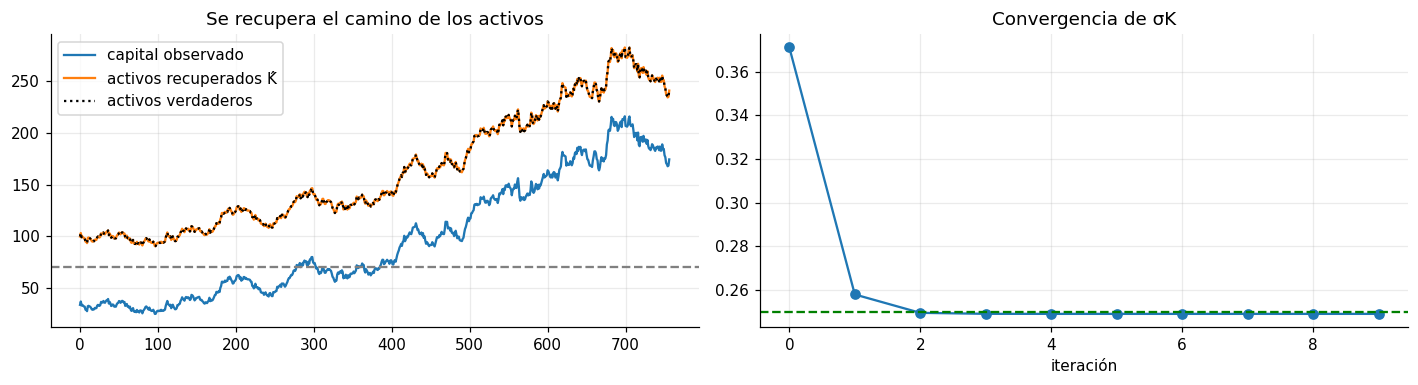

In [ ]:
# 4.1 Prueba controlada: verdad conocida -----------------------------------------
Kt, At = simulate(100, 70, .05, .12, .25, 1, 756, noise=0., seed=3)
sE_ = np.diff(np.log(At)).std(ddof=1)*np.sqrt(252); uno = solve_kmv(At[-1], sE_, 70, .05, 1)
km = kmv_iter(At, 70, .05, 1); mu_m, s_m = mle_duan(At, 70, .05, 1)
bs_dd, bs_pd, bs_sV = naive_bs(At[-1], 70, sE_, np.log(At[-1]/At[-253]))
print(pd.DataFrame({'σK': [.25, uno[1], km['sK'], s_m, bs_sV], 'μ': [.12, np.nan, km['mu'], mu_m, np.nan]}, index=['verdad', '① una sola σ_A', '② KMV iterativo', '③ MLE Duan', '④ ingenuo B–S']).round(4).to_string())
print(f"|σ_KMV − σ_MLE| / σ = {abs(km['sK'] - s_m)/km['sK']:.2%}  (Duan et al.: mismo punto; aquí ≈ por ddof y fin de muestra)")
print(f"Iteraciones KMV: {len(km['trace']) - 1}; σ por vuelta: {np.round(km['trace'][:6], 4)}")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6)); ax[0].plot(At, label='capital observado'); ax[0].plot(km['K'], label='activos recuperados K̂'); ax[0].plot(Kt, 'k:', label='activos verdaderos'); ax[0].axhline(70, color='gray', ls='--'); ax[0].legend(); ax[0].set(title='Se recupera el camino de los activos')
ax[1].plot(km['trace'], 'o-'); ax[1].axhline(.25, color='g', ls='--'); ax[1].set(title='Convergencia de σK', xlabel='iteración'); plt.tight_layout(); plt.show()

                   sesgo  desv.est.   RMSE
① una sola σ_A     0.037     0.0801 0.0879
② KMV iterativo  -0.0002      0.009 0.0089
④ B–S ingenuo σV  0.1522     0.0566 0.1623


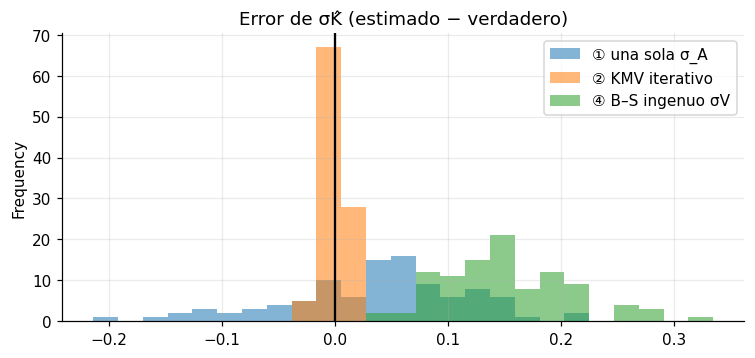

In [ ]:
# 4.2 ¿Quién se equivoca más? 100 repeticiones (n = 504 días) ---------------------
rep = {'① una sola σ_A': [], '② KMV iterativo': [], '④ B–S ingenuo σV': []}
for i in range(100):
    _, A_ = simulate(100, 70, .05, .12, .25, 1, 504, seed=1000 + i); sE = np.diff(np.log(A_)).std(ddof=1)*np.sqrt(252)
    rep['① una sola σ_A'].append(solve_kmv(A_[-1], sE, 70, .05, 1)[1] - .25); rep['② KMV iterativo'].append(kmv_iter(A_, 70, .05, 1)['sK'] - .25); rep['④ B–S ingenuo σV'].append(naive_bs(A_[-1], 70, sE, 0, 1)[2] - .25)
R_ = pd.DataFrame(rep); print(pd.DataFrame({'sesgo': R_.mean(), 'desv.est.': R_.std(), 'RMSE': np.sqrt((R_**2).mean())}).round(4).to_string())
R_.plot.hist(bins=25, alpha=.55, figsize=(8, 3.4), title='Error de σK̂ (estimado − verdadero)'); plt.axvline(0, color='k'); plt.show()

MODO = LIVE, n = 756 días
                           σK  K0 (mm)  DD KMV  d2 (μ=r)
① una σ_A (último día) 0.2103     1145   3.865     8.096
② KMV iterativo        0.2111     1145   3.849     8.062
③ MLE Duan              0.211     1145   3.852     8.068
④ ingenuo B–S          0.2295     1156   3.548     7.437


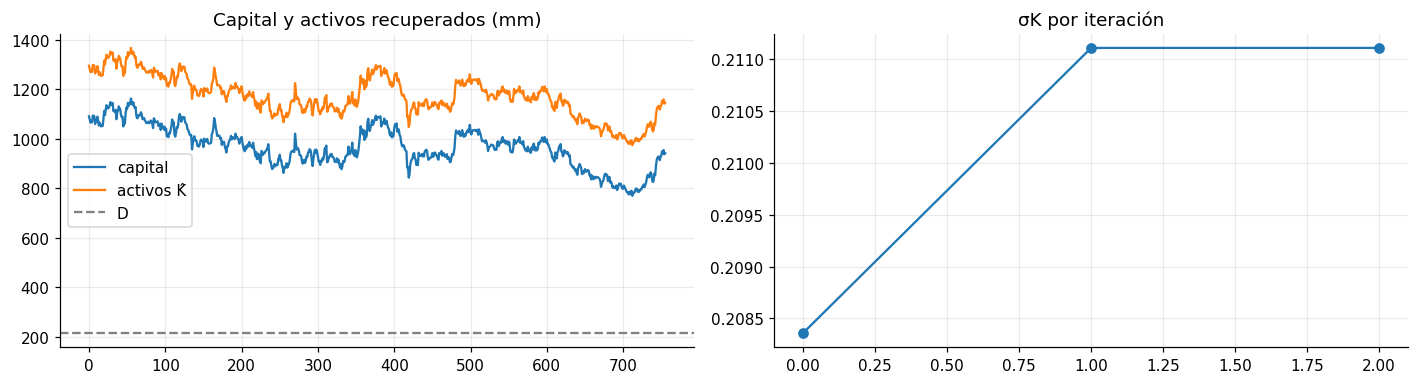

In [ ]:
# 4.3 Datos de mercado: KMV iterativo, MLE e ingenuo con la serie real (o simulada OFFLINE) --------
n_est = min(len(F['px']), 756); A_s = (F['px'].iloc[-n_est:]*F['shares']).values; D_ = F['D']
km = kmv_iter(A_s, D_, r, T); mu_m, s_m = mle_duan(A_s, D_, r, T, x0=(km['mu'], np.log(km['sK']))); rp = np.log(A_s[-1]/A_s[-min(253, n_est)])
bs_dd, bs_pd, bs_sV = naive_bs(A_s[-1], D_, km['sE'], rp, T); one = solve_kmv(A_s[-1], km['sE'], D_, r, T)
out = pd.DataFrame({'σK': [one[1], km['sK'], s_m, bs_sV], 'K0 (mm)': [one[0]/1e9, km['K'][-1]/1e9, invert(A_s[-1:], D_, r, s_m, T)[0]/1e9, (A_s[-1] + D_)/1e9]},
                   index=['① una σ_A (último día)', '② KMV iterativo', '③ MLE Duan', '④ ingenuo B–S'])
out['DD KMV'] = [dd_kmv(a*1e9, D_, b) for a, b in zip(out['K0 (mm)'], out['σK'])]; out['d2 (μ=r)'] = [d12(a*1e9, D_, r, b, T)[1] for a, b in zip(out['K0 (mm)'], out['σK'])]
print(f"MODO = {MODO}, n = {n_est} días"); print(out.round(4).to_string())
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6)); ax[0].plot(A_s/1e9, label='capital'); ax[0].plot(km['K']/1e9, label='activos K̂'); ax[0].axhline(D_/1e9, color='gray', ls='--', label='D'); ax[0].legend(); ax[0].set(title='Capital y activos recuperados (mm)')
ax[1].plot(km['trace'], 'o-'); ax[1].set(title='σK por iteración'); plt.tight_layout(); plt.show()

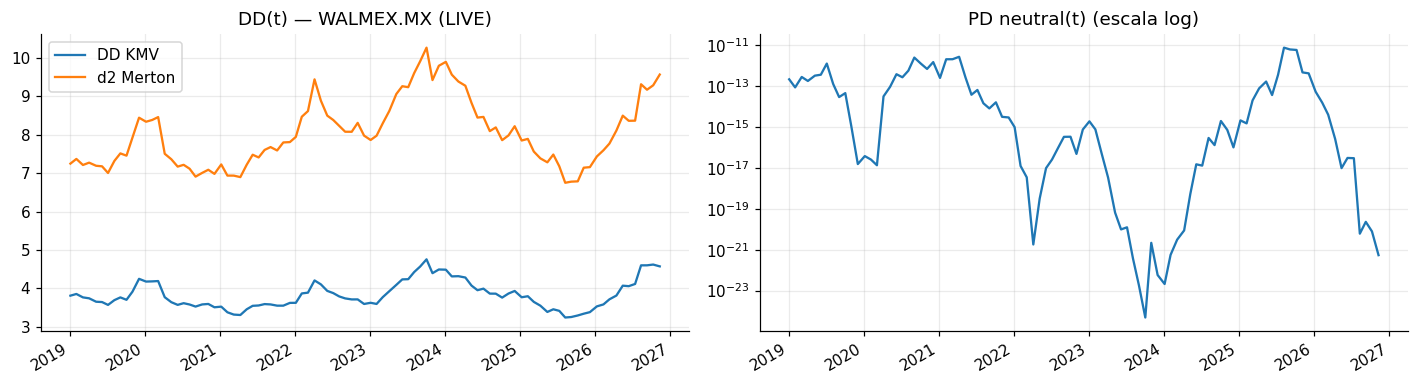

            DD KMV  d2 Merton  PD neutral
2026-07-13   4.112      8.367   2.958e-17
2026-08-11   4.597      9.316   6.048e-21
2026-09-09   4.598      9.173    2.29e-20
2026-10-09   4.618      9.289   7.817e-21
2026-11-10    4.57      9.569   5.388e-22


In [ ]:
# 4.4 DD(t): ventana móvil de 1 año, actualizada cada mes ----------------------
px = F['px']; fechas, dds, pds, dls = [], [], [], []
for j in range(252, len(px), 21):
    w = px.iloc[j - 252:j + 1]; sE_w = np.log(w).diff().std()*np.sqrt(252); A_w = w.iloc[-1]*F['shares']
    K_, s_, _, _ = solve_kmv(A_w, sE_w, F['D'], r, T); fechas.append(w.index[-1]); dds.append(dd_kmv(K_, F['D'], s_)); pds.append(merton(K_, F['D'], r, s_, T, r)['pdq']); dls.append(d12(K_, F['D'], r, s_, T)[1])
dd_t = pd.DataFrame({'DD KMV': dds, 'd2 Merton': dls, 'PD neutral': pds}, index=fechas)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6)); dd_t[['DD KMV', 'd2 Merton']].plot(ax=ax[0], title=f"DD(t) — {F['ticker']} ({MODO})"); dd_t['PD neutral'].clip(lower=1e-300).plot(ax=ax[1], logy=True, title='PD neutral(t) (escala log)'); plt.tight_layout(); plt.show()
print(dd_t.tail(5).to_string())

## 5. Extensiones
* **Black–Cox (1976):** el default ocurre la **primera vez** que $K_t\le B$. $\;P(\min_{t\le T}K_t\le B)=\Phi\!\big(\tfrac{b-mT}{\sigma\sqrt T}\big)+e^{2mb/\sigma^2}\Phi\!\big(\tfrac{b+mT}{\sigma\sqrt T}\big)$, $b=\ln(B/K_0)$, $m=\mu-\sigma^2/2$.
* **Saltos (Merton 1976):** $\ln K$ tiene saltos lognormales; con la **misma varianza total** se corrige la PD de corto plazo (el «problema del corto plazo» de la difusión pura).
* Se validan ambas fórmulas con Monte Carlo antes de usarlas.

Black–Cox  MC = 0.0888   fórmula = 0.0889
Saltos     MC = 0.1142   fórmula = 0.1142


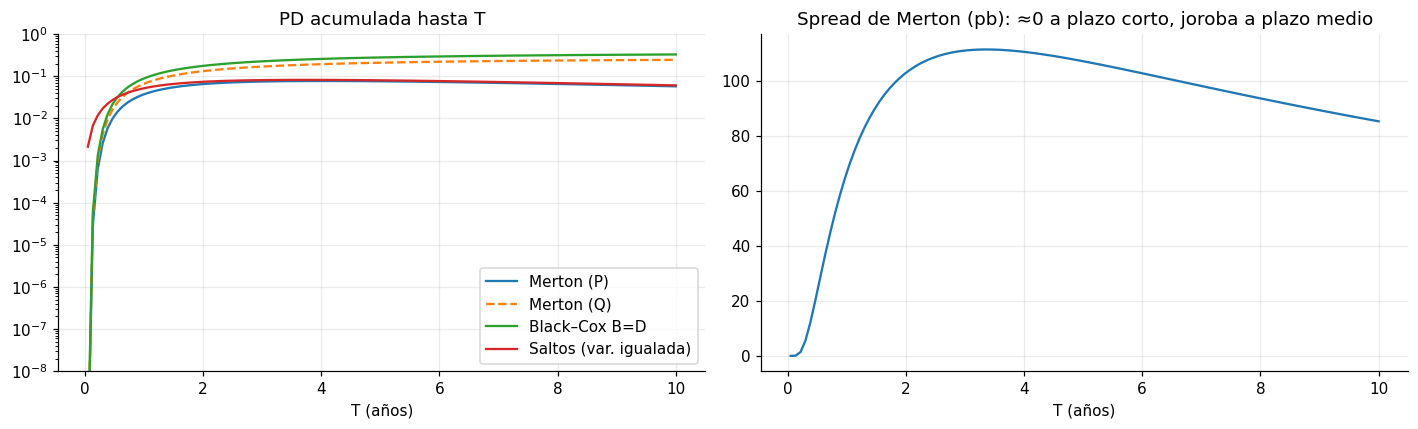

     Merton P  Black–Cox  Saltos
3 m    0.122%     0.257%  1.394%
1 a    3.740%     8.894%  5.206%
3 a    7.513%    22.667%  8.115%
5 a    7.609%    28.014%  8.024%


In [ ]:
# 5. Barrera y saltos: validación MC + curvas por plazo ----------------------------
rng = np.random.default_rng(5); K0, D, mu, s, T1 = 100., 70., .12, .25, 1.
# (a) Black–Cox por MC con corrección de puente browniano
M, n = 200000, 1000; h = T1/n; lk = np.full(M, np.log(K0)); b = np.log(D); hit = np.zeros(M, bool)
for _ in range(n):
    new = lk + (mu - .5*s*s)*h + s*np.sqrt(h)*rng.standard_normal(M); pc = np.where((lk > b) & (new > b), np.exp(-2*(lk - b)*(new - b)/(s*s*h)), 1.0)
    hit |= rng.random(M) < pc; lk = new
print(f'Black–Cox  MC = {hit.mean():.4f}   fórmula = {black_cox_pd(K0, D, mu, s, T1):.4f}')
# (b) saltos por MC
lam, mj, dj = 2., -.08, .15; k = np.exp(mj + .5*dj**2) - 1; Nj = rng.poisson(lam*T1, M)
lkT = np.log(K0) + (mu - .5*s*s - lam*k)*T1 + s*np.sqrt(T1)*rng.standard_normal(M) + Nj*mj + np.sqrt(Nj)*dj*rng.standard_normal(M)
print(f'Saltos     MC = {(lkT <= b).mean():.4f}   fórmula = {jump_pd(K0, D, mu, s, T1, lam, mj, dj)[0]:.4f}')

# (c) curvas por plazo con misma varianza total: σ_dif² = σ² − λ(μJ²+δJ²)
Ts = np.linspace(.05, 10, 120); lam, mj, dj = 1.5, -.12, .12; sd_ = np.sqrt(s*s - lam*(mj*mj + dj*dj))
pdm = np.array([merton(K0, D, .05, s, t, mu)['pdp'] for t in Ts]); pdq = np.array([merton(K0, D, .05, s, t, mu)['pdq'] for t in Ts])
fig, ax = plt.subplots(1, 2, figsize=(13, 4)); ax[0].semilogy(Ts, pdm, label='Merton (P)'); ax[0].semilogy(Ts, pdq, '--', label='Merton (Q)'); ax[0].semilogy(Ts, black_cox_pd(K0, D, mu, s, Ts), label='Black–Cox B=D'); ax[0].semilogy(Ts, jump_pd(K0, D, mu, sd_, Ts, lam, mj, dj), label='Saltos (var. igualada)')
ax[0].set(ylim=(1e-8, 1), xlabel='T (años)', title='PD acumulada hasta T'); ax[0].legend()
sp = np.array([merton(K0, D, .05, s, t)['spread'] for t in Ts])*1e4; ax[1].plot(Ts, sp); ax[1].set(title='Spread de Merton (pb): ≈0 a plazo corto, joroba a plazo medio', xlabel='T (años)'); plt.tight_layout(); plt.show()
print(pd.DataFrame({'Merton P': [merton(K0, D, .05, s, t, mu)['pdp'] for t in (.25, 1, 3, 5)], 'Black–Cox': black_cox_pd(K0, D, mu, s, np.array([.25, 1, 3, 5])), 'Saltos': jump_pd(K0, D, mu, sd_, np.array([.25, 1, 3, 5]), lam, mj, dj)}, index=['3 m', '1 a', '3 a', '5 a']).to_string(float_format='{:.3%}'.format))

## 6. Del DD a la EDF empírica (la segunda opción del PDF)
KMV no usa $\Phi(-\mathrm{DD})$: arma una base de empresas con su DD, deja pasar un año y calcula **EDF(DD) = quebrados / empresas con ese DD**. Aquí se simula esa base con **colas $t_\nu$** e **incertidumbre de la volatilidad**: en un mundo normal Merton funciona; en uno realista la EDF a DD≈3–4 es mucho mayor que la de Merton en logaritmos.

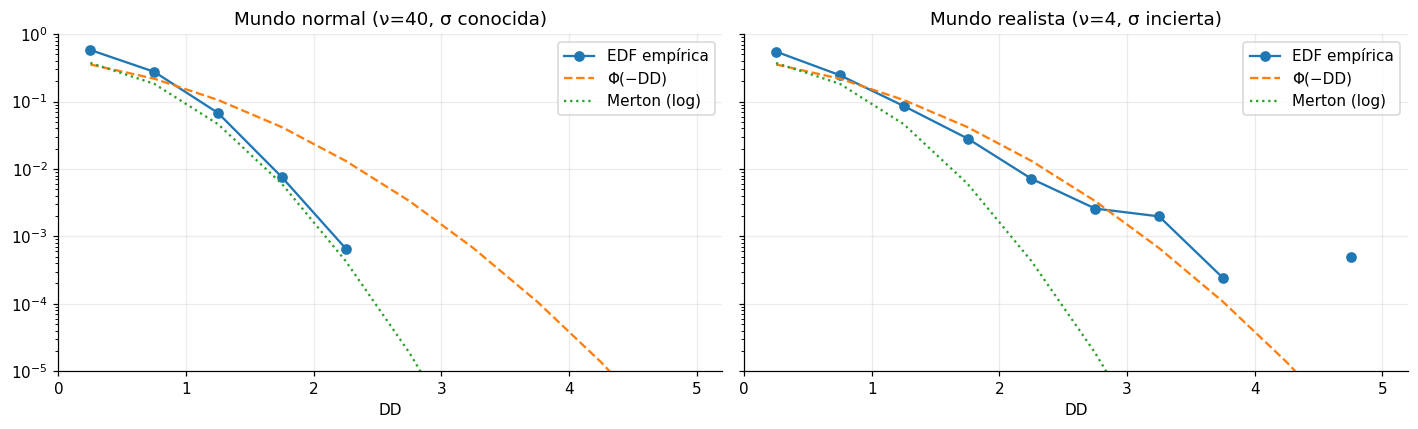

            n  quiebras   phi_DD  merton_log  EDF_emp
2.0–2.5  9078        65 1.32e-02    4.31e-04 7.16e-03
2.5–3.0  7352        19 3.34e-03    1.86e-05 2.58e-03
3.0–3.5  5554        11 6.70e-04    4.81e-07 1.98e-03
3.5–4.0  4125         1 1.08e-04    8.43e-09 2.42e-04
4.0–4.5  2932         0 1.36e-05    9.83e-11 0.00e+00
4.5–5.0  2007         1 1.35e-06    5.55e-13 4.98e-04


In [ ]:
# 6. EDF empírica vectorizada ---------------------------------------------------------
def edf_empirica(nf=60000, nu=4, vv=.4, mu=.06, seed=11, bw=.5, nb=16):
    rng = np.random.default_rng(seed); L = np.clip(rng.beta(2, 3, nf), .02, .97); s0 = .25*np.exp(.45*rng.standard_normal(nf)); dd = (1 - L)/s0
    sr = s0*np.exp(vv*rng.standard_normal(nf) - vv**2/2); lk = np.zeros(nf); hit = np.zeros(nf, bool); sc = 1. if nu >= 40 else np.sqrt((nu - 2)/nu)
    for _ in range(12):                                   # 12 observaciones mensuales
        e = rng.standard_normal(nf) if nu >= 40 else rng.standard_t(nu, nf)*sc
        lk += (mu - .5*sr**2)/12 + sr/np.sqrt(12)*e; hit |= lk <= np.log(L)
    bi = np.floor(dd/bw).astype(int); ok = bi < nb
    df = pd.DataFrame(dict(b=bi[ok], d=hit[ok], nm=N(-dd[ok]), pm=N(-dd_mer(1, L[ok], s0[ok], 1, mu)))).groupby('b').agg(n=('d', 'size'), quiebras=('d', 'sum'), phi_DD=('nm', 'mean'), merton_log=('pm', 'mean'))
    df['EDF_emp'] = df.quiebras/df.n; df.index = [f'{i*bw:.1f}–{(i + 1)*bw:.1f}' for i in df.index]; return df
mundos = {'Mundo normal (ν=40, σ conocida)': edf_empirica(nu=40, vv=0), 'Mundo realista (ν=4, σ incierta)': edf_empirica(nu=4, vv=.4)}
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, (nom, df) in zip(ax, mundos.items()):
    x = np.arange(len(df))*.5 + .25; e = df.EDF_emp.where(df.quiebras > 0); a.semilogy(x, e, 'o-', label='EDF empírica'); a.semilogy(x, df.phi_DD, '--', label='Φ(−DD)'); a.semilogy(x, df.merton_log, ':', label='Merton (log)')
    a.set(title=nom, xlabel='DD', ylim=(1e-5, 1), xlim=(0, 5.2)); a.legend()
plt.tight_layout(); plt.show(); print(mundos['Mundo realista (ν=4, σ incierta)'].iloc[4:10].to_string(float_format='{:.2e}'.format))

## 7. Cartera: correlación de activos, Gaussian copula y Vasicek
Para cada empresa: PD real de Merton $\to$ umbral $\Phi^{-1}(\mathrm{PD}_i)$. La **correlación de activos** se estima con los rendimientos de $\hat K_t$ (activos recuperados por KMV) y se simula la pérdida con una *Gaussian copula*; se compara con la aproximación de **un factor** (Vasicek / Basilea IRB, el «modelo de valor crítico de un factor» del PDF).

[GFNORTEO.MX] yfinance falló (ValueError: datos incompletos en Yahoo) → snapshot OFFLINE
[ELEKTRA.MX] yfinance falló (ValueError: datos incompletos en Yahoo) → snapshot OFFLINE
MODO cartera = OFFLINE | 10 empresas | 505 días
           D_K     sK  mu_hat     DD     PD  LGD_end
ticker                                              
Firma1  0.6213 0.2601  0.3496  1.456 0.0204   0.0919
Firma2  0.7186 0.3627 -0.2376 0.7757 0.1641   0.1708
Firma3  0.5003 0.3565  0.6514  1.402 0.0219   0.1218
Firma4  0.5986  0.287  0.3077  1.399 0.0251   0.1027
Firma5  0.5524 0.1819 -0.0168   2.46 0.0001   0.0443
Firma6  0.4002 0.2208  0.0164  2.716      0   0.0452
Firma7  0.6807 0.3654 -0.1507 0.8739 0.1321   0.1639
Firma8  0.4329 0.3052  0.0417  1.858  0.002   0.0847
Firma9  0.6508 0.3989 -0.0877 0.8756 0.1349   0.1768
Firma10 0.6633 0.2563  0.1063  1.314  0.034   0.0969

Correlación de activos promedio (observada) ρ̄ = 0.322


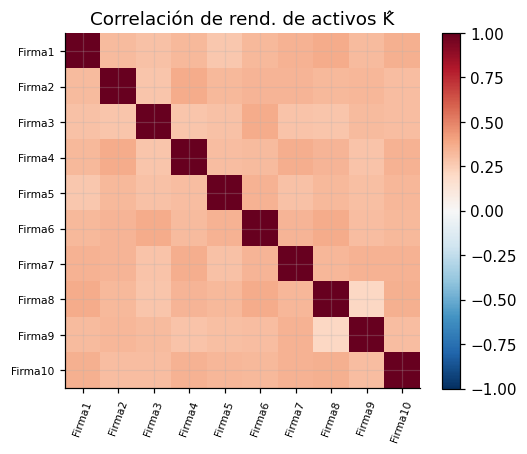

In [ ]:
# 7.1 Universo de empresas (LIVE si hay red; si no, universo simulado con un factor común) ------------
TICKERS = ['WALMEX.MX', 'AMXB.MX', 'GFNORTEO.MX', 'CEMEXCPO.MX', 'GMEXICOB.MX', 'FEMSAUBD.MX', 'BIMBOA.MX', 'ELEKTRA.MX']
def universo(tickers=TICKERS, use_yf=USE_YF, nf=10):
    f0 = load_firm(tickers[0], use_yf=use_yf)               # si la 1a falla (sin red) no insistimos con las demás
    if f0['modo'] == 'LIVE':
        firmas = [f0] + [load_firm(t) for t in tickers[1:]]
        if all(f['modo'] == 'LIVE' for f in firmas):
            px = pd.concat({f['ticker']: f['px'] for f in firmas}, axis=1).dropna().iloc[-504:]; return firmas, px, 'LIVE'
    rng = np.random.default_rng(21); n = 504; zc = rng.standard_normal(n); rows = []; cols = {}
    for i in range(nf):                                       # universo sintético: 1 factor común (ρ_f=.35), σ y apalancamiento heterogéneos
        s = rng.uniform(.18, .45); L = rng.uniform(.40, .80); rho_f = .35
        z = np.sqrt(rho_f)*zc + np.sqrt(1 - rho_f)*rng.standard_normal(n); K = 100*np.exp(np.concatenate([[0], np.cumsum((.07 - .5*s*s)*H + s*np.sqrt(H)*z)]))
        D_ = L*K[-1]; cols[f'Firma{i + 1}'] = call(K, D_, .05, s, 1.); rows.append(dict(ticker=f'Firma{i + 1}', modo='OFFLINE', shares=1., std=.7*D_, ltd=.6*D_, tl=1.3*D_, mcap=cols[f'Firma{i + 1}'][-1]))
    return rows, pd.DataFrame(cols, index=pd.bdate_range(end='2022-06-13', periods=n + 1)), 'OFFLINE'
firmas, PX, MODO7 = universo(); print('MODO cartera =', MODO7, '|', len(firmas), 'empresas |', len(PX), 'días')
PRIMA = .04      # μ = r + prima supuesta: el μ̂ de la serie tiene error ≈ σ/√años (≈15–25 pp con 2–3 años), inservible para PD
res = []
for f in firmas:
    A_ = (PX[f['ticker']]*f['shares']).values; D_ = f['std'] + .5*f['ltd']; km = kmv_iter(A_, D_, .05, 1.); K_ = km['K'][-1]
    m_ = merton(K_, D_, .05, km['sK'], 1., .05 + PRIMA); res.append(dict(ticker=f['ticker'], D_K=D_/K_, sK=km['sK'], mu_hat=km['mu'], DD=dd_kmv(K_, D_, km['sK']), PD=max(m_['pdp'], 1e-6), LGD_end=m_['lgd'], dK=np.diff(np.log(km['K']))))
U = pd.DataFrame(res).set_index('ticker'); print(U.drop(columns='dK').round(4).to_string())
Cm = np.corrcoef(np.vstack(U.dK.values)); rho_bar = (Cm.sum() - len(Cm))/(len(Cm)*(len(Cm) - 1)); print(f'\nCorrelación de activos promedio (observada) ρ̄ = {rho_bar:.3f}')
plt.figure(figsize=(5.2, 4.2)); plt.imshow(Cm, cmap='RdBu_r', vmin=-1, vmax=1); plt.xticks(range(len(U)), U.index, rotation=70, fontsize=7); plt.yticks(range(len(U)), U.index, fontsize=7); plt.colorbar(); plt.title('Correlación de rend. de activos K̂'); plt.show()

                                EL      σ  VaR 99.0%  ES 99.0%
independiente (ρ=0)         0.2399 0.3077        0.9    0.9512
un factor, ρ̄=0.32          0.2415 0.3912        1.8     1.934
copula con matriz observada 0.2404 0.3924        1.8     1.949
VaR asintótico (ASRF, ρ̄) = 1.2459  (sin granularidad: con 10 empresas el MC es la referencia)


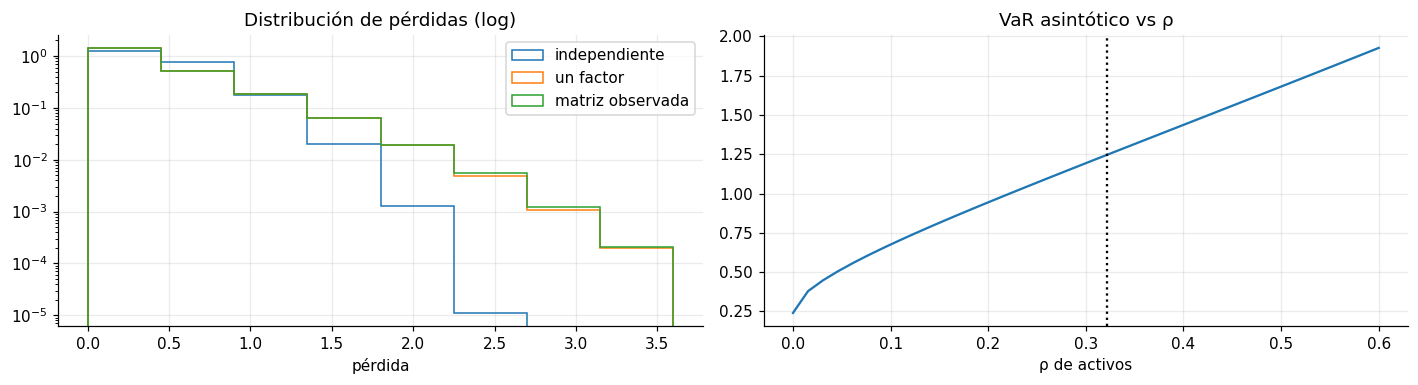


ρ_EDF (fórmula del PDF) con EDF_X=2%, EDF_Y=3%:
ρ_activos=0.1   0.0166
ρ_activos=0.3   0.0707
ρ_activos=0.5   0.1619
ρ_activos=0.7   0.3092


In [ ]:
# 7.2 Pérdida de la cartera: copula con matriz observada vs un factor con ρ̄ ----------------------------
rng = np.random.default_rng(3); M = 200000; n = len(U); pdv = U.PD.values; th = norm.ppf(pdv); ead = np.ones(n); lg = .45; al = .99
Lc = np.linalg.cholesky(Cm + 1e-8*np.eye(n)); Z = rng.standard_normal((M, n)) @ Lc.T; loss_c = ((Z <= th)*ead*lg).sum(1)
z0 = rng.standard_normal((M, 1)); X1 = np.sqrt(max(rho_bar, 0))*z0 + np.sqrt(1 - max(rho_bar, 0))*rng.standard_normal((M, n)); loss_1 = ((X1 <= th)*ead*lg).sum(1)
ind = (rng.standard_normal((M, n)) <= th); loss_0 = (ind*ead*lg).sum(1)
q = lambda x: np.quantile(x, al); es = lambda x: x[x >= q(x)].mean()
asrf = sum(lg*ead[i]*N((th[i] + np.sqrt(rho_bar)*norm.ppf(al))/np.sqrt(1 - rho_bar)) for i in range(n))
print(pd.DataFrame({'EL': [x.mean() for x in (loss_0, loss_1, loss_c)], 'σ': [x.std() for x in (loss_0, loss_1, loss_c)], f'VaR {al:.1%}': [q(x) for x in (loss_0, loss_1, loss_c)], f'ES {al:.1%}': [es(x) for x in (loss_0, loss_1, loss_c)]},
                   index=['independiente (ρ=0)', f'un factor, ρ̄={rho_bar:.2f}', 'copula con matriz observada']).round(4).to_string()); print(f'VaR asintótico (ASRF, ρ̄) = {asrf:.4f}  (sin granularidad: con {n} empresas el MC es la referencia)')
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6)); b_ = np.arange(0, loss_c.max() + .45, .45*lg/.45)
for x, nom in ((loss_0, 'independiente'), (loss_1, 'un factor'), (loss_c, 'matriz observada')): ax[0].hist(x, b_, histtype='step', density=True, label=nom)
ax[0].set(yscale='log', title='Distribución de pérdidas (log)', xlabel='pérdida'); ax[0].legend()
rr = np.linspace(0, .6, 40); ax[1].plot(rr, [sum(lg*N((th[i] + np.sqrt(x)*norm.ppf(al))/np.sqrt(1 - x)) for i in range(n)) for x in rr]); ax[1].axvline(rho_bar, color='k', ls=':'); ax[1].set(title='VaR asintótico vs ρ', xlabel='ρ de activos'); plt.tight_layout(); plt.show()
p1, p2 = .02, .03; print('\nρ_EDF (fórmula del PDF) con EDF_X=2%, EDF_Y=3%:'); print(pd.Series({f'ρ_activos={ra}': rho_edf(p1, p2, ra)[0] for ra in (.1, .3, .5, .7)}).round(4).to_string())

## 8. Ejercicios recreacional (extras)
1. **Punto de default.** En §3 cambia `defs` y mide cuánto se mueve la DD de WALMEX al pasar de «sólo CP» a «CP + LP». ¿Por qué *no* se mueve la DD lineal y sí $d_2$? (Pista: $\ln(K_0/D)$ vs $(K_0-D)/K_0$ cuando $K_0\gg D$.)
2. **Una empresa en problemas.** Usa $A_0=5$, $D=100$, $\sigma_A=100\%$ en `solve_kmv`. ¿Converge Newton? ¿Qué $\eta$ resulta? Dibuja la sección 3 con estos datos.
3. **Ruido de precio.** En §4.1 llama `simulate(..., noise=.02)`. ¿Qué pasa con $\hat\sigma_K$ en KMV vs MLE? ¿Qué supuesto del modelo se rompe?
4. **Horizonte.** Recalcula la tabla de §3 con `T=3` y `T=0.25`. ¿La PD sube o baja? ¿Depende del apalancamiento?
5. **Colas.** En §6 prueba $\nu\in\{3,4,6,10,40\}$ y `vv`$\in\{0,.2,.4,.6\}$. ¿A partir de qué combinación la EDF empírica supera a $\Phi(-\mathrm{DD})$ en DD=3–4?
6. **Correlación.** En §7.2 reemplaza `Cm` por una matriz con $\rho=.1$ y otra con $\rho=.5$ (todas iguales fuera de la diagonal). ¿Cómo cambian VaR y ES? ¿Y $\rho_{EDF}$?
7. **Para pensar.** Un banco con apalancamiento 10× ¿es buen candidato para Merton? ¿Qué es «deuda» y «punto de default» ahí?
8. **Mercado mexicano.** KMV advierte que en acciones poco líquidas la volatilidad se subestima. Compara $\sigma_A$ de dos emisoras líquidas y una poco líquida (cambia `TICKERS`).

## 9. Referencias:

Merton (1974) *J. Finance* 29(2) · Black & Cox (1976) *J. Finance* 31(2) · Merton (1976) *JFE* 3 · Leland & Toft (1996) *J. Finance* 51(3) · Crosbie & Bohn (2003) *Modeling Default Risk*, Moody's KMV · Duan (1994) *Math. Finance* 4(2) · Duan, Gauthier & Simonato (2005) *On the equivalence of the KMV and ML methods*, GERAD G-2005-06 · Bharath & Shumway (2008) *Rev. Financial Studies* 21(3) · Vasicek (2002) *Risk* 15(12).
Moody's KMV: *default point ≈ pasivos de corto plazo + ½ de largo plazo* (CreditEdge Quick Reference).